# First-Order Logic (FOL) Forward Chaining Solver
This notebook implements a simple forward chaining solver for First-Order Logic (FOL) Horn clauses. It allows you to define a Knowledge Base (KB) consisting of rules and facts, and then query the KB to derive new conclusions.

In [34]:
import re

class FOLParser:
    @staticmethod
    def parse_literal(literal_str):
        """Parses a literal string like 'Parent(x, y)' into (predicate, arguments) tuple."""
        literal_str = literal_str.strip()
        match = re.match(r'^~?([a-zA-Z_][a-zA-Z0-9_]*)\((.*)\)$', literal_str)
        if not match:
            raise ValueError(f"Invalid literal format: {literal_str}")
        pred = match.group(1)
        args = [arg.strip() for arg in match.group(2).split(',') if arg.strip()]
        return pred, args

    @staticmethod
    def parse_rule(rule_str):
        """Parses a rule string like 'Parent(x, y) & Male(x) => Father(x, y)' into (premises, conclusion)."""
        if '=>' not in rule_str:
            raise ValueError(f"Invalid rule format (missing =>): {rule_str}")
        premises_str, conclusion_str = rule_str.split('=>')

        premises = []
        for p_str in premises_str.split('&'):
            if p_str.strip():
                premises.append(FOLParser.parse_literal(p_str))

        conclusion = FOLParser.parse_literal(conclusion_str)
        return premises, conclusion

    @staticmethod
    def parse_fact(fact_str):
        """Parses a ground fact like 'Parent(John, Bob)'."""
        return FOLParser.parse_literal(fact_str)

In [35]:
def is_variable(x):
    return isinstance(x, str) and x[0].islower()

def is_constant(x):
    return isinstance(x, str) and x[0].isupper()

def unify_var(var, val, subst):
    if var in subst:
        return unify(subst[var], val, subst)
    elif val in subst:
        return unify(var, subst[val], subst)
    else:
        subst[var] = val
        return subst

def unify(x, y, subst=None):
    """Unifies expressions x and y with an optional initial substitution."""
    if subst is None:
        subst = {}
    if subst is False:
        return False
    if x == y:
        return subst
    if is_variable(x):
        return unify_var(x, y, subst)
    if is_variable(y):
        return unify_var(y, x, subst)
    if isinstance(x, list) and isinstance(y, list):
        if len(x) != len(y):
            return False
        for xi, yi in zip(x, y):
            subst = unify(xi, yi, subst)
            if subst is False:
                return False
        return subst
    if isinstance(x, tuple) and isinstance(y, tuple):
        if x[0] != y[0]:
            return False
        return unify(list(x[1]), list(y[1]), subst)
    return False

def substitute(subst, expr):
    """Applies substitutions to a literal expression."""
    pred, args = expr
    new_args = [subst.get(arg, arg) if is_variable(arg) else arg for arg in args]
    return pred, tuple(new_args)

In [36]:
class FOLForwardChaining:
    def __init__(self):
        self.rules = []
        self.facts = set()  # Stored as (predicate, (arg1, arg2, ...))

    def add_rule(self, rule_str):
        premises, conclusion = FOLParser.parse_rule(rule_str)
        self.rules.append((premises, conclusion))

    def add_fact(self, fact_str):
        pred, args = FOLParser.parse_fact(fact_str)
        self.facts.add((pred, tuple(args)))

    def run(self, verbose=True):
        """Runs forward chaining until no new facts can be derived."""
        new_derived = True
        step = 1

        if verbose:
            print("--- Starting Forward Chaining Inference ---")
            print(f"Initial Facts: {list(self.facts)}\n")

        while new_derived:
            new_derived = False
            new_facts_this_iteration = set()

            for premises, conclusion in self.rules:
                # Find all substitutions that satisfy premises
                substitutions = [{}]

                for premise in premises:
                    next_substitutions = []
                    for subst in substitutions:
                        # Apply current substitutions to current premise
                        substituted_premise = substitute(subst, premise)
                        # Try to unify with existing facts
                        for fact in self.facts:
                            unify_res = unify(substituted_premise, fact, subst.copy())
                            if unify_res is not False:
                                next_substitutions.append(unify_res)
                    substitutions = next_substitutions

                # Derive new conclusions based on substitutions
                for subst in substitutions:
                    derived_fact = substitute(subst, conclusion)
                    # Check if derived fact contains unresolved variables
                    if any(is_variable(arg) for arg in derived_fact[1]):
                        continue # Only derive ground facts

                    if derived_fact not in self.facts and derived_fact not in new_facts_this_iteration:
                        new_facts_this_iteration.add(derived_fact)
                        if verbose:
                            print(f"Step {step}: Derived {derived_fact[0]}({', '.join(derived_fact[1])}) using rule {premises} => {conclusion} with {subst}")
                            step += 1

            if new_facts_this_iteration:
                self.facts.update(new_facts_this_iteration)
                new_derived = True

        if verbose:
            print("\n--- Inference Completed ---")
            print(f"Final Facts Knowledge Base: {list(self.facts)}")

In [40]:
# Example with fixed ground constants (uppercase starting letter) for correct forward chaining unification
fc = FOLForwardChaining()

# Add rules
fc.add_rule("Fever(p) & SoreThroat(p) => InfectionSign(p)")
fc.add_rule("InfectionSign(p) & MuscleAches(p) => TestFlu(p)")

# Add Facts (Using 'Patient' as a ground constant rather than variable 'p')
fc.add_fact("Fever(Patient)")
fc.add_fact("SoreThroat(Patient)")
fc.add_fact("MuscleAches(Patient)")

# Run
fc.run()

--- Starting Forward Chaining Inference ---
Initial Facts: [('MuscleAches', ('Patient',)), ('Fever', ('Patient',)), ('SoreThroat', ('Patient',))]

Step 1: Derived InfectionSign(Patient) using rule [('Fever', ['p']), ('SoreThroat', ['p'])] => ('InfectionSign', ['p']) with {'p': 'Patient'}
Step 2: Derived TestFlu(Patient) using rule [('InfectionSign', ['p']), ('MuscleAches', ['p'])] => ('TestFlu', ['p']) with {'p': 'Patient'}

--- Inference Completed ---
Final Facts Knowledge Base: [('MuscleAches', ('Patient',)), ('SoreThroat', ('Patient',)), ('TestFlu', ('Patient',)), ('InfectionSign', ('Patient',)), ('Fever', ('Patient',))]


### Visualizing the Inference Graph
We will use `networkx` to build a directed graph of our knowledge base, showing how base facts combine via rules to derive the final conclusions (like `Criminal(West)`).

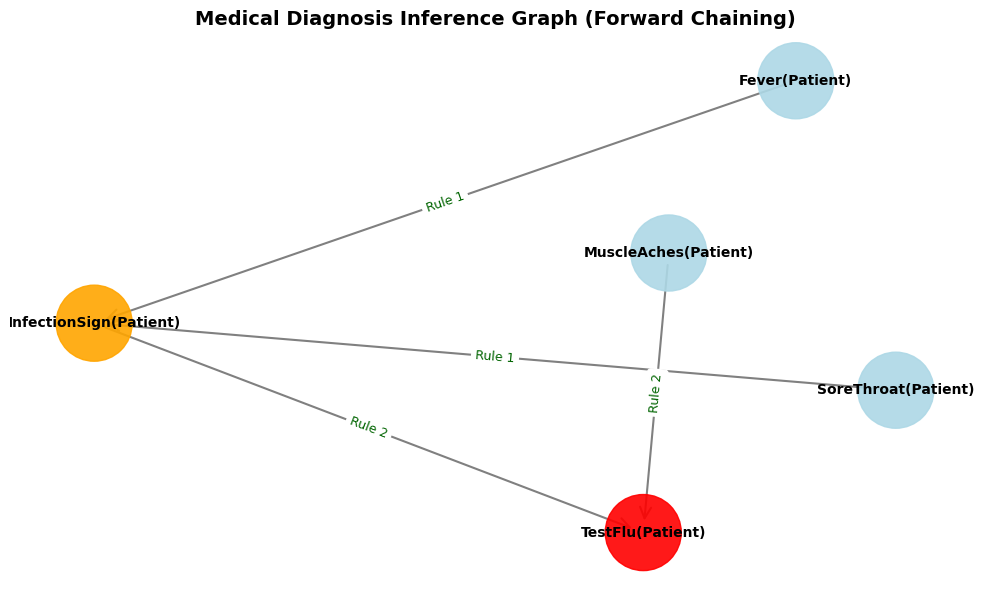

In [41]:
import networkx as nx
import matplotlib.pyplot as plt

# Create a directed graph
G = nx.DiGraph()

def fact_to_str(fact):
    return f"{fact[0]}({', '.join(fact[1])})"

# Dynamic identification of base facts containing the actual constant 'Patient'
base_facts_set = {('Fever', ('Patient',)), ('SoreThroat', ('Patient',)), ('MuscleAches', ('Patient',))}

# Build nodes dynamically from execution
for fact in fc.facts:
    fact_str = fact_to_str(fact)
    if fact in base_facts_set:
        G.add_node(fact_str, type='fact', color='lightblue')
    else:
        node_type = 'conclusion' if fact[0] == 'TestFlu' else 'derived'
        node_color = 'red' if node_type == 'conclusion' else 'orange'
        G.add_node(fact_str, type=node_type, color=node_color)

# Graph connections matching actual unified output
# 1. Fever(Patient) & SoreThroat(Patient) => InfectionSign(Patient)
G.add_node('InfectionSign(Patient)', type='derived', color='orange')
G.add_edge('Fever(Patient)', 'InfectionSign(Patient)', label='Rule 1')
G.add_edge('SoreThroat(Patient)', 'InfectionSign(Patient)', label='Rule 1')

# 2. InfectionSign(Patient) & MuscleAches(Patient) => TestFlu(Patient)
G.add_node('TestFlu(Patient)', type='conclusion', color='red')
G.add_edge('InfectionSign(Patient)', 'TestFlu(Patient)', label='Rule 2')
G.add_edge('MuscleAches(Patient)', 'TestFlu(Patient)', label='Rule 2')

# Plotting the graph
plt.figure(figsize=(10, 6))
pos = nx.spring_layout(G, seed=42, k=1.2)

node_colors = [nx.get_node_attributes(G, 'color').get(node, 'orange') for node in G.nodes()]

xn = nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=3000, alpha=0.9)
xe = nx.draw_networkx_edges(G, pos, arrowstyle='->', arrowsize=20, edge_color='gray', width=1.5)
xl = nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

edge_labels = nx.get_edge_attributes(G, 'label')
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_color='darkgreen', font_size=9)

plt.title("Medical Diagnosis Inference Graph (Forward Chaining)", fontsize=14, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()